# B-KIPR01-XX1-N01 – KI-Programmierung

**Name:** Mücahid Emin Tomakin  
**Matrikelnummer:** *30042741*  
**Studiengangnummer:** *Künstliche Intelligenz und Maschinelles Lernen*  
**Einsendeaufgabencode:** B-KIPR01-XX1-N01  
**Variante:** 1  
**Datum:** *03.10.2026*  

**Bezogene Studienhefte:** KIPR00, KIPR01, KIPRBU  

---

## Hinweise zur Umsetzung

- **Gymnasium-Version:** `LunarLander-v2` ist in der aktuellen Gymnasium-Version nicht mehr verfügbar; es wird daher `LunarLander-v3` verwendet. Die Observations-, Aktions- und Reward-Struktur ist identisch.
- Alle Abbildungen und Tabellen sind eigene Darstellungen auf Basis der selbst erzeugten Simulationsdaten.
- Der trainierte PPO-Agent wird zwischengespeichert, damit die Episoden-Erhebung reproduzierbar bleibt.
- Der Zufallsseed ist global auf `TK_SEED = 42` gesetzt.

In [1]:
# =========================================================
# Setup: Imports, Konfiguration, Pfade
# =========================================================

import os
import shutil
import numpy as np
import pandas as pd
import seaborn as sns
import gymnasium as gym
import tensorflow as tf
import keras_tuner as kt
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow import keras
from scipy.stats import ks_2samp
from stable_baselines3 import PPO
from IPython.display import display
from sklearn.model_selection import train_test_split
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.evaluation import evaluate_policy

# --- Globale Konfiguration ---
TK_ENV_ID = "LunarLander-v3"   # v2 in aktueller Gymnasium-Version nicht verfügbar
TK_SEED = 42
TK_N_ENVS = 4
TK_N_EPISODES = 50

TK_MODEL_DIR = Path("../models")
TK_DATA_DIR = Path("../data")
TK_FIG_DIR = Path("../figures")

TK_PPO_MODEL_PATH = TK_MODEL_DIR / "TomaKing_PPO_LunarLander"
TK_SURROGATE_BASELINE_PATH = TK_MODEL_DIR / "TomaKing_A4_Surrogat_Baseline.keras"
TK_SURROGATE_ES_PATH = TK_MODEL_DIR / "TomaKing_A5_Surrogat_EarlyStopping.keras"
TK_SURROGATE_TUNED_PATH = TK_MODEL_DIR / "TomaKing_A5_Surrogat_Tuned.keras"
TK_TUNER_DIR = TK_MODEL_DIR / "TomaKing_A5_KerasTuner"

TK_ACTION_LABELS = {
    0: "noop (0)",
    1: "left (1)",
    2: "main (2)",
    3: "right (3)",
}
TK_FUEL_MAP = {0: 0, 1: 1, 2: 5, 3: 1}

TK_OBS_COLS = [f"obs_{i}" for i in range(8)]
TK_NEXT_OBS_COLS = [f"next_obs_{i}" for i in range(8)]
TK_DIM_NAMES = [
    "x-Position", "y-Position",
    "vx", "vy", "Winkel", "Winkelgeschw.",
    "Kontakt links", "Kontakt rechts",
]
TK_REDUCTION_FRACTIONS = [0.50, 0.30, 0.20, 0.10, 0.05]

# --- Verzeichnisse anlegen ---
for tk_dir in (TK_MODEL_DIR, TK_DATA_DIR, TK_FIG_DIR):
    tk_dir.mkdir(parents=True, exist_ok=True)

# --- Reproduzierbarkeit ---
np.random.seed(TK_SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

# --- Kontrollausgabe ---
display(pd.DataFrame({
    "Parameter": ["ENV_ID", "SEED", "Anzahl Envs", "PPO-Modell vorhanden"],
    "Wert": [
        TK_ENV_ID,
        TK_SEED,
        TK_N_ENVS,
        TK_PPO_MODEL_PATH.with_suffix(".zip").exists(),
    ],
}))

,Parameter,Wert
0,ENV_ID,LunarLander-v3
1,SEED,42
2,Anzahl Envs,4
3,PPO-Modell vorhanden,True


## Aufgabe 1 – Datenerhebung und Exploration (20 Punkte)

**Ziel:** Eine feste Anzahl von Episoden (50) mit dem trainierten PPO-Agenten durchlaufen lassen und den resultierenden Datensatz explorieren.

**Vorgehen:**
1. PPO-Agent trainieren (bzw. aus `../models/TomaKing_PPO_LunarLander.zip` laden).
2. 50 Episoden sequentiell durchlaufen; pro Schritt `episode_id`, `step`, `action`, `reward`, `obs_0…obs_7`, `next_obs_0…next_obs_7`, `terminated`, `truncated` erfassen.
3. Pro Episode `length`, `total_reward`, `terminated`, `truncated` aggregieren.
4. Deskriptive Statistik, Top-/Bottom-5-Episoden und Korrelation zwischen Länge und Reward analysieren.
5. Visualisierungen: Boxplots, Histogramme, Scatterplot, Aktionsverteilung.

In [2]:
# =========================================================
# Hilfsfunktionen (global)
# =========================================================
def tk_prepare_xy(df):
    """Erzeugt X (obs + one-hot action) und Y (next_obs) aus einem DataFrame."""
    obs = df[TK_OBS_COLS].to_numpy(dtype=np.float32)
    next_obs = df[TK_NEXT_OBS_COLS].to_numpy(dtype=np.float32)
    actions = df["action"].to_numpy(dtype=np.int64)
    action_onehot = keras.utils.to_categorical(actions, num_classes=4).astype(np.float32)
    X = np.concatenate([obs, action_onehot], axis=1)
    return X, next_obs

def tk_split_70_15_15(X, Y, seed=TK_SEED):
    """Splittet in 70 % Train, 15 % Val, 15 % Test."""
    X_tmp, X_test, Y_tmp, Y_test = train_test_split(
        X, Y, test_size=0.15, random_state=seed
    )
    X_train, X_val, Y_train, Y_val = train_test_split(
        X_tmp, Y_tmp, test_size=0.1765, random_state=seed
    )
    return X_train, X_val, X_test, Y_train, Y_val, Y_test

def tk_a4_build_surrogate_model(input_dim=12, output_dim=8, n_units=64):
    """MLP mit integrierter Normalisierung."""
    tk_normalizer = keras.layers.Normalization(axis=-1)
    tk_model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        tk_normalizer,
        keras.layers.Dense(n_units, activation="relu"),
        keras.layers.Dense(n_units, activation="relu"),
        keras.layers.Dense(output_dim, activation="linear"),
    ])
    tk_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=["mae"],
    )
    return tk_model, tk_normalizer

In [3]:
# =========================================================
# PPO-Agent laden oder trainieren
# =========================================================
tk_vec_env = make_vec_env(TK_ENV_ID, n_envs=TK_N_ENVS, seed=TK_SEED)

if TK_PPO_MODEL_PATH.with_suffix(".zip").exists():
    tk_agent = PPO.load(str(TK_PPO_MODEL_PATH), env=tk_vec_env)
else:
    tk_agent = PPO(
        policy="MlpPolicy",
        env=tk_vec_env,
        n_steps=1024,
        batch_size=64,
        gae_lambda=0.98,
        gamma=0.999,
        n_epochs=4,
        ent_coef=0.01,
        seed=TK_SEED,
        verbose=0,
    )
    tk_agent.learn(total_timesteps=1_500_000)
    tk_agent.save(str(TK_PPO_MODEL_PATH))

# Kurzevaluation des geladenen Agents
tk_mean_reward, tk_std_reward = evaluate_policy(tk_agent, tk_vec_env, n_eval_episodes=10)

display(pd.DataFrame({
    "Kennzahl": ["Mittlerer Reward", "Standardabweichung"],
    "Wert": [round(tk_mean_reward, 2), round(tk_std_reward, 2)],
}))

,Kennzahl,Wert
0,Mittlerer Reward,283.77
1,Standardabweichung,15.17


In [4]:
# =========================================================
# Aufgabe 1: Episoden mit dem Agenten aufzeichnen
# =========================================================
def tk_a1_collect_episodes(tk_agent, tk_env_id, tk_n_episodes, tk_seed):
    """Durchläuft n Episoden im Agenten und liefert Steps- und Episoden-DataFrame."""
    tk_env_single = gym.make(tk_env_id, render_mode=None)
    tk_steps_records = []
    tk_episodes_records = []

    for tk_ep_id in range(tk_n_episodes):
        tk_obs, tk_info = tk_env_single.reset(seed=tk_seed + tk_ep_id)
        tk_ep_reward = 0.0
        tk_step = 0
        tk_terminated = False
        tk_truncated = False

        while not (tk_terminated or tk_truncated):
            tk_action, _ = tk_agent.predict(tk_obs, deterministic=True)
            tk_next_obs, tk_reward, tk_terminated, tk_truncated, tk_info = tk_env_single.step(tk_action)

            tk_steps_records.append({
                "episode_id": tk_ep_id,
                "step": tk_step,
                "action": int(tk_action),
                "reward": float(tk_reward),
                **{f"obs_{i}": float(v) for i, v in enumerate(tk_obs)},
                **{f"next_obs_{i}": float(v) for i, v in enumerate(tk_next_obs)},
                "terminated": bool(tk_terminated),
                "truncated": bool(tk_truncated),
            })

            tk_obs = tk_next_obs
            tk_ep_reward += tk_reward
            tk_step += 1

        tk_episodes_records.append({
            "episode_id": tk_ep_id,
            "length": tk_step,
            "total_reward": tk_ep_reward,
            "terminated": bool(tk_terminated),
            "truncated": bool(tk_truncated),
        })

    tk_env_single.close()
    return pd.DataFrame(tk_steps_records), pd.DataFrame(tk_episodes_records)


tk_steps_df, tk_episodes_df = tk_a1_collect_episodes(
    tk_agent, TK_ENV_ID, TK_N_EPISODES, TK_SEED
)

display(pd.DataFrame({
    "Kennzahl": ["Schritte gesamt", "Episoden gesamt"],
    "Wert": [len(tk_steps_df), len(tk_episodes_df)],
}))
display(tk_episodes_df.head())

,Kennzahl,Wert
0,Schritte gesamt,11337
1,Episoden gesamt,50


,episode_id,length,total_reward,terminated,truncated
0,0,233,270.120671,True,False
1,1,203,276.749058,True,False
2,2,257,306.657228,True,False
3,3,227,267.080577,True,False
4,4,229,294.773071,True,False


In [5]:
# =========================================================
# Aufgabe 1: Deskriptive Statistik
# =========================================================
display(tk_episodes_df[["length", "total_reward"]].describe().round(2))

tk_mean_reward = tk_episodes_df["total_reward"].mean()
tk_std_reward = tk_episodes_df["total_reward"].std()

display(pd.DataFrame({
    "Kennzahl": ["Mittlerer Reward", "Std. Reward"],
    "Wert": [round(tk_mean_reward, 2), round(tk_std_reward, 2)],
}))

display(tk_episodes_df.nlargest(5, "total_reward")[["episode_id", "length", "total_reward"]])
display(tk_episodes_df.nsmallest(5, "total_reward")[["episode_id", "length", "total_reward"]])

tk_best_ep = tk_episodes_df.loc[tk_episodes_df["total_reward"].idxmax()]
tk_worst_ep = tk_episodes_df.loc[tk_episodes_df["total_reward"].idxmin()]

tk_corr_pearson_len = tk_episodes_df["length"].corr(tk_episodes_df["total_reward"], method="pearson")
tk_corr_spearman_len = tk_episodes_df["length"].corr(tk_episodes_df["total_reward"], method="spearman")

display(pd.DataFrame({
    "Kennzahl": [
        "Beste Episode",
        "Bester Reward",
        "Länge beste Episode",
        "Schlechteste Episode",
        "Schlechtester Reward",
        "Länge schlechteste Episode",
        "Pearson Länge↔Reward",
        "Spearman Länge↔Reward",
    ],
    "Wert": [
        int(tk_best_ep["episode_id"]),
        round(tk_best_ep["total_reward"], 2),
        int(tk_best_ep["length"]),
        int(tk_worst_ep["episode_id"]),
        round(tk_worst_ep["total_reward"], 2),
        int(tk_worst_ep["length"]),
        round(tk_corr_pearson_len, 3),
        round(tk_corr_spearman_len, 3),
    ],
}))

,length,total_reward
count,50.00,50.00
mean,226.74,281.77
std,19.22,20.60
min,190.00,247.86
25%,213.50,263.15
50%,226.50,281.65
75%,238.00,298.10
max,267.00,318.23


,Kennzahl,Wert
0,Mittlerer Reward,281.77
1,Std. Reward,20.60


,episode_id,length,total_reward
33,33,209,318.229401
45,45,201,316.798199
15,15,255,316.018977
43,43,267,312.327690
27,27,215,310.360417


,episode_id,length,total_reward
48,48,234,247.863994
6,6,205,247.964616
19,19,216,249.307917
11,11,228,249.749621
31,31,244,253.720691


,Kennzahl,Wert
0,Beste Episode,33.000
1,Bester Reward,318.230
2,Länge beste Episode,209.000
3,Schlechteste Episode,48.000
4,Schlechtester Reward,247.860
5,Länge schlechteste Episode,234.000
6,Pearson Länge↔Reward,0.081
7,Spearman Länge↔Reward,0.045


### Interpretation Aufgabe 1

- **Erfolg des Agenten:** Der Agent erreicht im Mittel einen Reward von rund **281,77 ± 20,60** über 50 Episoden. Das ist deutlich über dem typischen Schwellenwert von 200, den LunarLander als "gelöst" betrachtet.
- **Beste Episode:** Episode **#33** mit Reward **318,23** bei Länge **209**.  
  **Schlechteste Episode:** Episode **#48** mit Reward **247,86** bei Länge **234**.
- **Episodenlänge:** Im Schnitt **226,74 ± 19,22** Schritte, Range 190–267.
- **Korrelation Länge ↔ Reward:** Pearson **0,081**, Spearman **0,045**.  
  Die Korrelation ist praktisch null. Das ist plausibel, denn ein längeres Überleben bedeutet nicht automatisch einen höheren kumulativen Reward, wenn der Agent viel Zeit im schwebenden, passiven Zustand (noop) verbringt.

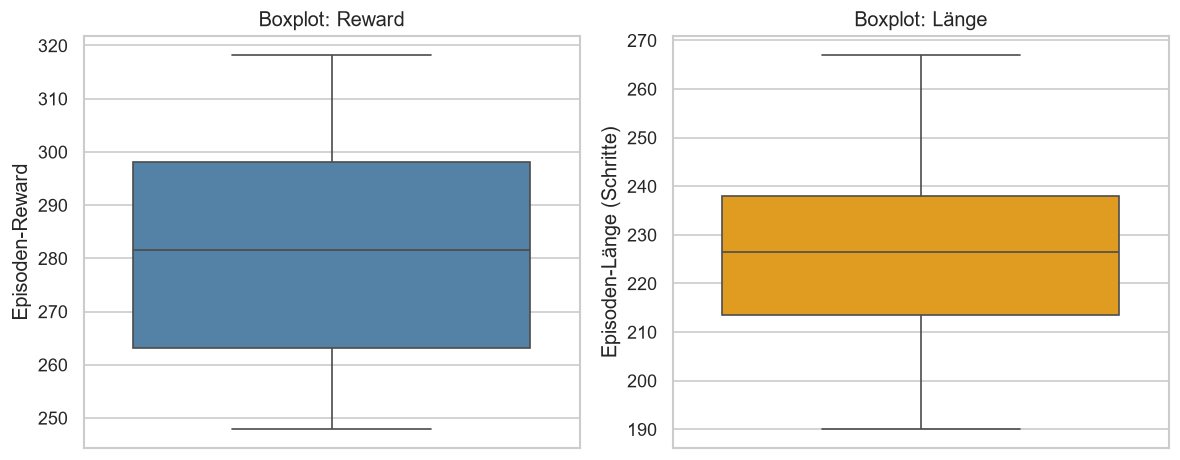

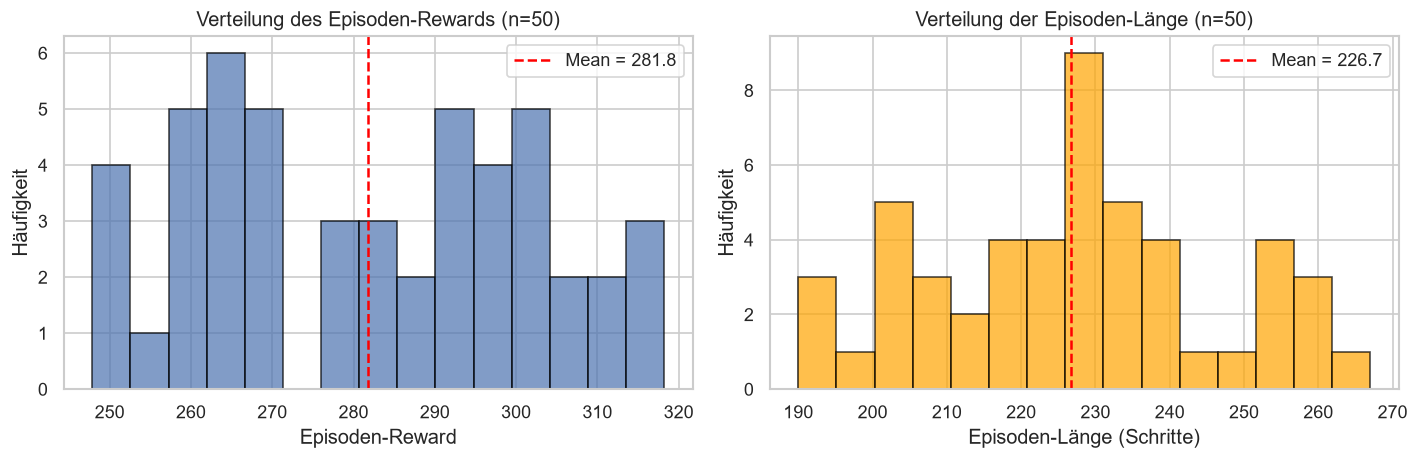

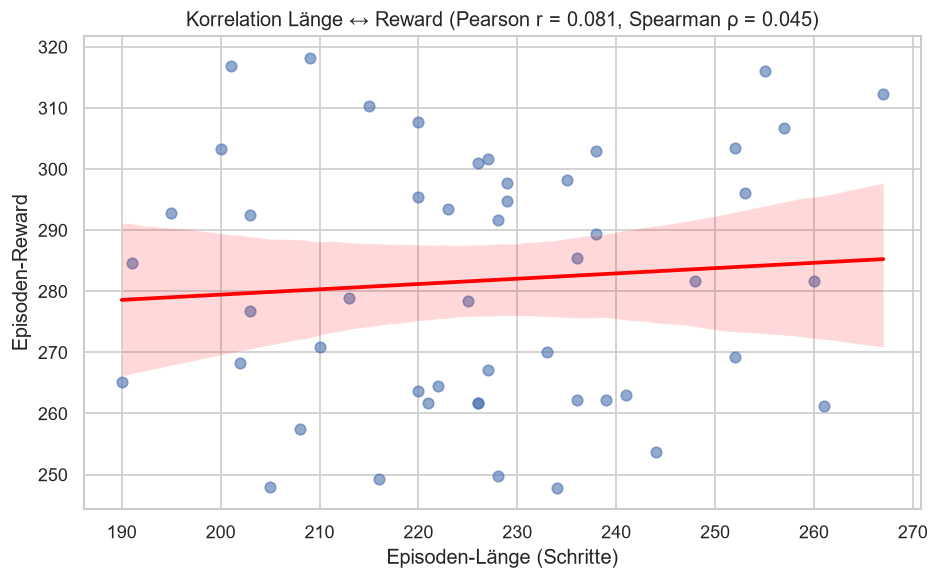

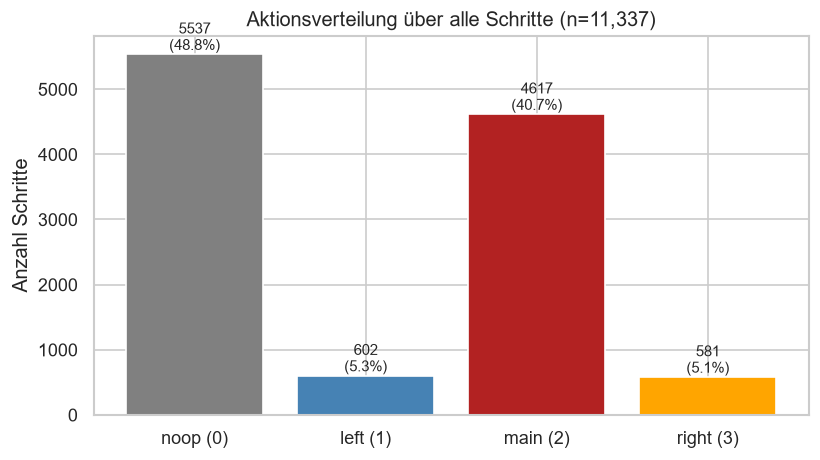

,Aktion,Anzahl,Anteil (%)
0,noop (0),5537,48.8
1,left (1),602,5.3
2,main (2),4617,40.7
3,right (3),581,5.1


In [6]:
# =========================================================
# Aufgabe 1: Visualisierung – Boxplots, Histogramme, Scatter
# =========================================================
# --- Boxplots ---
tk_fig, tk_axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=tk_episodes_df["total_reward"], ax=tk_axes[0], color="steelblue")
tk_axes[0].set_ylabel("Episoden-Reward")
tk_axes[0].set_title("Boxplot: Reward")

sns.boxplot(y=tk_episodes_df["length"], ax=tk_axes[1], color="orange")
tk_axes[1].set_ylabel("Episoden-Länge (Schritte)")
tk_axes[1].set_title("Boxplot: Länge")

tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A1_Boxplot_Reward_Laenge.png", bbox_inches="tight")
plt.show()

# --- Histogramme ---
tk_fig, tk_axes = plt.subplots(1, 2, figsize=(12, 4))
tk_axes[0].hist(tk_episodes_df["total_reward"], bins=15, edgecolor="black", alpha=0.7)
tk_axes[0].axvline(tk_episodes_df["total_reward"].mean(), color="red", linestyle="--",
                   label=f"Mean = {tk_episodes_df['total_reward'].mean():.1f}")
tk_axes[0].set_xlabel("Episoden-Reward")
tk_axes[0].set_ylabel("Häufigkeit")
tk_axes[0].set_title(f"Verteilung des Episoden-Rewards (n={len(tk_episodes_df)})")
tk_axes[0].legend()

tk_axes[1].hist(tk_episodes_df["length"], bins=15, edgecolor="black", alpha=0.7, color="orange")
tk_axes[1].axvline(tk_episodes_df["length"].mean(), color="red", linestyle="--",
                   label=f"Mean = {tk_episodes_df['length'].mean():.1f}")
tk_axes[1].set_xlabel("Episoden-Länge (Schritte)")
tk_axes[1].set_ylabel("Häufigkeit")
tk_axes[1].set_title(f"Verteilung der Episoden-Länge (n={len(tk_episodes_df)})")
tk_axes[1].legend()

tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A1_Histogramme_Reward_Laenge.png", bbox_inches="tight")
plt.show()

# --- Scatterplot Länge vs. Reward ---
tk_fig, tk_ax = plt.subplots(figsize=(8, 5))
sns.regplot(
    data=tk_episodes_df, x="length", y="total_reward",
    scatter_kws={"alpha": 0.6, "s": 40},
    line_kws={"color": "red"},
    ax=tk_ax,
)
tk_ax.set_xlabel("Episoden-Länge (Schritte)")
tk_ax.set_ylabel("Episoden-Reward")
tk_ax.set_title(
    f"Korrelation Länge ↔ Reward "
    f"(Pearson r = {tk_corr_pearson_len:.3f}, Spearman ρ = {tk_corr_spearman_len:.3f})"
)
tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A1_Scatter_Laenge_Reward.png", bbox_inches="tight")
plt.show()

# --- Aktionsverteilung ---
tk_action_counts = tk_steps_df["action"].value_counts().sort_index()

tk_fig, tk_ax = plt.subplots(figsize=(7, 4))
tk_bars = tk_ax.bar(
    [TK_ACTION_LABELS[i] for i in tk_action_counts.index],
    tk_action_counts.values,
    color=["grey", "steelblue", "firebrick", "orange"],
)
for tk_bar, tk_v in zip(tk_bars, tk_action_counts.values):
    tk_ax.text(
        tk_bar.get_x() + tk_bar.get_width() / 2,
        tk_bar.get_height(),
        f"{tk_v}\n({tk_v / len(tk_steps_df) * 100:.1f}%)",
        ha="center", va="bottom", fontsize=9,
    )
tk_ax.set_ylabel("Anzahl Schritte")
tk_ax.set_title(f"Aktionsverteilung über alle Schritte (n={len(tk_steps_df):,})")
tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A1_Aktionsverteilung.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "Aktion": [TK_ACTION_LABELS[i] for i in tk_action_counts.index],
    "Anzahl": tk_action_counts.values,
    "Anteil (%)": (tk_action_counts.values / len(tk_steps_df) * 100).round(1),
}))

**Aktionsverteilung:** Der Agent nutzt überwiegend `noop` (48,8 %) und `main` (40,7 %). Die Seitenkorrekturen `left` (5,3 %) und `right` (5,1 %) kommen selten vor. Das passt zum trainierten Verhalten eines LunarLander-Agenten, der in der Landephase nur punktuell korrigiert.

In [7]:
# =========================================================
# Persistenz: DataFrames aus Aufgabe 1 sichern
# =========================================================
tk_steps_df.to_csv(TK_DATA_DIR / "TomaKing_A1_steps.csv", index=False)
tk_episodes_df.to_csv(TK_DATA_DIR / "TomaKing_A1_episodes.csv", index=False)

display(pd.DataFrame({
    "Datei": ["TomaKing_A1_steps.csv", "TomaKing_A1_episodes.csv"],
    "Pfad": [str(TK_DATA_DIR / "TomaKing_A1_steps.csv"),
             str(TK_DATA_DIR / "TomaKing_A1_episodes.csv")],
    "Zeilen": [len(tk_steps_df), len(tk_episodes_df)],
}))

,Datei,Pfad,Zeilen
0,TomaKing_A1_steps.csv,..\data\TomaKing_A1_steps.csv,11337
1,TomaKing_A1_episodes.csv,..\data\TomaKing_A1_episodes.csv,50


## Aufgabe 2 – Fuel-Feature (20 Punkte)

**Ziel:** Feature Engineering für den Treibstoffverbrauch.

**Mapping (laut Aufgabenstellung):**

| Aktion | Fuel-Verbrauch |
|---|---|
| noop (0) | 0 |
| left (1) | 1 |
| main (2) | 5 |
| right (3) | 1 |

Der Treibstoffverbrauch wird pro Schritt erfasst und pro Episode aufsummiert.

In [8]:
# =========================================================
# Aufgabe 2: Fuel pro Schritt und pro Episode
# =========================================================
tk_steps_df["fuel_step"] = tk_steps_df["action"].map(TK_FUEL_MAP).astype(int)

tk_fuel_per_episode = (
    tk_steps_df.groupby("episode_id")["fuel_step"]
    .sum()
    .rename("fuel_episode")
)
tk_episodes_df = tk_episodes_df.merge(tk_fuel_per_episode, on="episode_id", how="left")

# --- Validierung ---
display(pd.DataFrame({
    "Prüfung": [
        "Schritte mit fuel_step == 0 (noop)",
        "Schritte mit fuel_step == 1 (left/right)",
        "Schritte mit fuel_step == 5 (main)",
        "Summe fuel_step (alle Schritte)",
        "Summe fuel_episode (alle Episoden)",
    ],
    "Wert": [
        int((tk_steps_df["fuel_step"] == 0).sum()),
        int((tk_steps_df["fuel_step"] == 1).sum()),
        int((tk_steps_df["fuel_step"] == 5).sum()),
        int(tk_steps_df["fuel_step"].sum()),
        int(tk_episodes_df["fuel_episode"].sum()),
    ],
}))

display(tk_episodes_df["fuel_episode"].describe().round(2))

,Prüfung,Wert
0,Schritte mit fuel_step == 0 (noop),5537
1,Schritte mit fuel_step == 1 (left/right),1183
2,Schritte mit fuel_step == 5 (main),4617
3,Summe fuel_step (alle Schritte),24268
4,Summe fuel_episode (alle Episoden),24268


count     50.00
mean     485.36
std       28.04
min      427.00
25%      462.50
50%      487.50
75%      505.00
max      547.00
Name: fuel_episode, dtype: float64

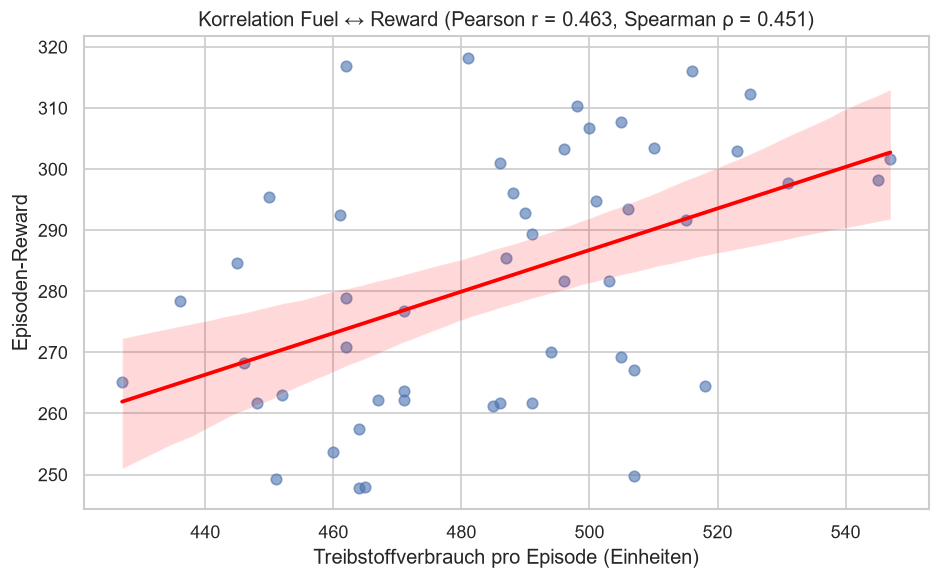

,Kennzahl,Wert
0,Pearson Fuel↔Reward,0.463
1,Spearman Fuel↔Reward,0.451


In [9]:
# =========================================================
# Aufgabe 2: Fuel vs. Reward
# =========================================================
tk_corr_pearson_fuel = tk_episodes_df["fuel_episode"].corr(tk_episodes_df["total_reward"], method="pearson")
tk_corr_spearman_fuel = tk_episodes_df["fuel_episode"].corr(tk_episodes_df["total_reward"], method="spearman")

tk_fig, tk_ax = plt.subplots(figsize=(8, 5))
sns.regplot(
    data=tk_episodes_df, x="fuel_episode", y="total_reward",
    scatter_kws={"alpha": 0.6, "s": 40},
    line_kws={"color": "red"},
    ax=tk_ax,
)
tk_ax.set_xlabel("Treibstoffverbrauch pro Episode (Einheiten)")
tk_ax.set_ylabel("Episoden-Reward")
tk_ax.set_title(
    f"Korrelation Fuel ↔ Reward "
    f"(Pearson r = {tk_corr_pearson_fuel:.3f}, Spearman ρ = {tk_corr_spearman_fuel:.3f})"
)
tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A2_Fuel_vs_Reward.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "Kennzahl": ["Pearson Fuel↔Reward", "Spearman Fuel↔Reward"],
    "Wert": [round(tk_corr_pearson_fuel, 3), round(tk_corr_spearman_fuel, 3)],
}))

### Interpretation Aufgabe 2

- **Fuel-Verbrauch:** Im Mittel **485,36 ± 28,04** Einheiten pro Episode (Range 427–547).
- **Validierung:** Summe `fuel_step` = Summe `fuel_episode` = **24.268** — die Aggregation ist konsistent.
- **Korrelation Fuel ↔ Reward:** Pearson **0,463**, Spearman **0,451**.  
  Es gibt einen **mittleren positiven Zusammenhang**: Episoden mit mehr Treibstoffverbrauch erzielen tendenziell höhere Rewards. Das ist plausibel, weil mehr aktives Manövrieren (main, left, right) mit mehr Positionskontrolle und damit erfolgreicheren Landungen einhergeht — `noop` verbraucht keinen Treibstoff, bringt aber auch keinen Fortschritt.

In [10]:
# =========================================================
# Aufgabe 2: DataFrames mit Fuel-Feature erneut speichern
# =========================================================
tk_steps_df.to_csv(TK_DATA_DIR / "TomaKing_A1_steps.csv", index=False)
tk_episodes_df.to_csv(TK_DATA_DIR / "TomaKing_A1_episodes.csv", index=False)

display(pd.DataFrame({
    "DataFrame": ["tk_steps_df", "tk_episodes_df"],
    "Spalten": [", ".join(tk_steps_df.columns), ", ".join(tk_episodes_df.columns)],
}))

,DataFrame,Spalten
0,tk_steps_df,"episode_id, step, action, reward, obs_0, obs_1..."
1,tk_episodes_df,"episode_id, length, total_reward, terminated, ..."


## Aufgabe 3 – Fuel-Quartile vs. Reward (10 Punkte)

**Ziel:** Prüfen, ob der Treibstoffverbrauch den Reward erklärt, indem die Episoden in Quartile des Fuel-Verbrauchs aufgeteilt werden.

,count,mean,std,min,max
fuel_quartile,,,,,
Q1 (niedrig),13,275.28,18.66,249.31,316.80
Q2,12,270.47,21.33,247.86,318.23
Q3,13,289.66,15.84,261.75,310.36
Q4 (hoch),12,291.56,20.37,249.75,316.02


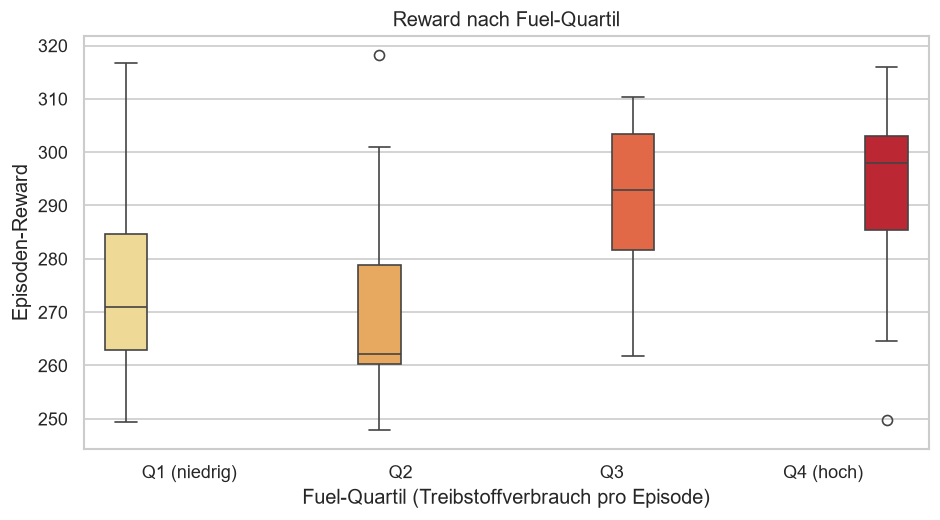

In [11]:
# =========================================================
# Aufgabe 3: Reward pro Fuel-Quartil
# =========================================================
tk_episodes_df["fuel_quartile"] = pd.qcut(
    tk_episodes_df["fuel_episode"], q=4,
    labels=["Q1 (niedrig)", "Q2", "Q3", "Q4 (hoch)"],
)

tk_fuel_summary = (
    tk_episodes_df.groupby("fuel_quartile", observed=True)["total_reward"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)
display(tk_fuel_summary)

tk_fig, tk_ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(
    data=tk_episodes_df, x="fuel_quartile", y="total_reward",
    hue="fuel_quartile", palette="YlOrRd", legend=False, ax=tk_ax,
)
tk_ax.set_xlabel("Fuel-Quartil (Treibstoffverbrauch pro Episode)")
tk_ax.set_ylabel("Episoden-Reward")
tk_ax.set_title("Reward nach Fuel-Quartil")
tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A3_Reward_nach_Fuel_Quartil.png", bbox_inches="tight")
plt.show()

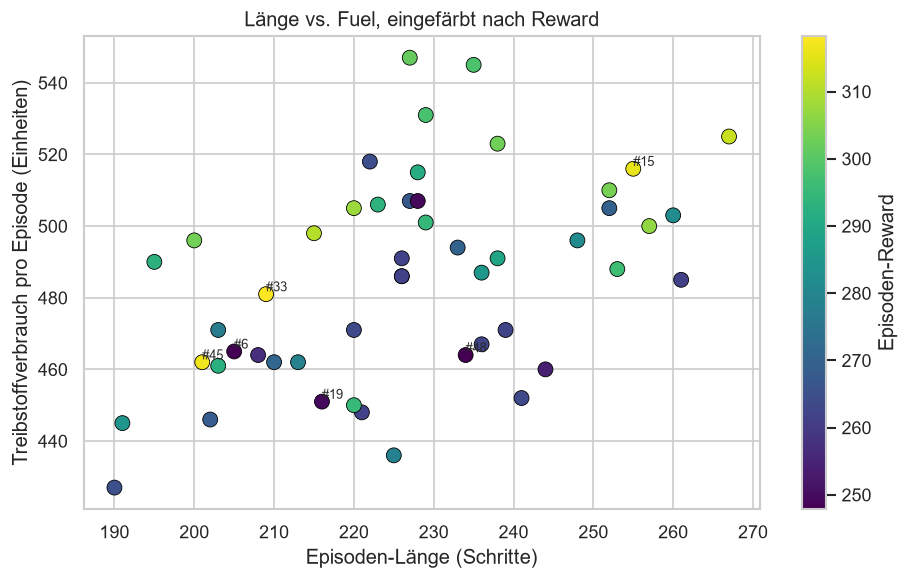

,Kennzahl,Wert
0,Pearson Länge↔Fuel,0.474


In [12]:
# =========================================================
# Aufgabe 3: Länge vs. Fuel, eingefärbt nach Reward
# =========================================================
tk_corr_len_fuel = tk_episodes_df["length"].corr(tk_episodes_df["fuel_episode"], method="pearson")

tk_fig, tk_ax = plt.subplots(figsize=(8, 5))
tk_sc = tk_ax.scatter(
    tk_episodes_df["length"], tk_episodes_df["fuel_episode"],
    c=tk_episodes_df["total_reward"], cmap="viridis", s=80,
    edgecolor="black", linewidth=0.5,
)
plt.colorbar(tk_sc, ax=tk_ax, label="Episoden-Reward")

for _, tk_row in pd.concat([
    tk_episodes_df.nlargest(3, "total_reward"),
    tk_episodes_df.nsmallest(3, "total_reward"),
]).iterrows():
    tk_ax.annotate(
        f"#{int(tk_row['episode_id'])}",
        (tk_row["length"], tk_row["fuel_episode"]),
        fontsize=8, ha="left", va="bottom",
    )

tk_ax.set_xlabel("Episoden-Länge (Schritte)")
tk_ax.set_ylabel("Treibstoffverbrauch pro Episode (Einheiten)")
tk_ax.set_title("Länge vs. Fuel, eingefärbt nach Reward")
tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A3_Laenge_vs_Fuel.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "Kennzahl": ["Pearson Länge↔Fuel"],
    "Wert": [round(tk_corr_len_fuel, 3)],
}))

### Interpretation Aufgabe 3

**Reward pro Fuel-Quartil:**

| Quartil | n | Mean | Std |
|---|---|---|---|
| Q1 (niedrig) | 13 | 275,28 | 18,66 |
| Q2 | 12 | 270,47 | 21,33 |
| Q3 | 13 | 289,66 | 15,84 |
| Q4 (hoch) | 12 | 291,56 | 20,37 |

- **Tendenz:** Q3 und Q4 zeigen höhere mittlere Rewards (~290) als Q1 und Q2 (~270–275).  
  Der Zusammenhang ist **positiv, aber nicht streng monoton** — Q1 liegt über Q2. Das ist bei nur 50 Episoden erwartbar (Stichprobenrauschen).
- **Beitrag des Features:** Fuel trägt zur Erklärung des Rewards bei (siehe Aufgabe 2: Pearson r ≈ 0,46), ist aber kein alleiniger Prädiktor. Die Quartilsanalyse zeigt den Zusammenhang robuster als eine einzelne Korrelation, weil Ausreißer weniger stark wirken.
- **Länge ↔ Fuel:** Pearson **0,474**. Längere Episoden verbrauchen mehr Treibstoff — plausibel, weil in jedem Schritt eine Aktion gewählt wird.

## Aufgabe 4 – Surrogatmodell (20 Punkte)

**Ziel:** Ein künstliches neuronales Netz als Surrogat für die Simulationsumgebung trainieren.

**Architektur:**
- **Features:** `obs_0…obs_7` (8 Dimensionen) + One-Hot-codierte Aktion (4 Dimensionen) = 12 Eingaben
- **Zielwerte:** `next_obs_0…next_obs_7` (8 Dimensionen)
- **Modell:** MLP mit zwei versteckten Schichten (64 Neuronen, ReLU) und linearer Ausgabe
- **Loss:** MSE, **Optimizer:** Adam (lr = 1e-3), **Metrik:** MAE
- **Split:** 70/15/15 (Train/Val/Test), `random_state=TK_SEED`

In [13]:
# =========================================================
# Aufgabe 4: Daten für Surrogatmodell vorbereiten
# =========================================================
tf.random.set_seed(TK_SEED)
np.random.seed(TK_SEED)

X, Y = tk_prepare_xy(tk_steps_df)
X_train, X_val, X_test, Y_train, Y_val, Y_test = tk_split_70_15_15(X, Y)

display(pd.DataFrame({
    "Split": ["X (gesamt)", "X_train", "X_val", "X_test"],
    "Shape": [X.shape, X_train.shape, X_val.shape, X_test.shape],
}))

,Split,Shape
0,X (gesamt),"(11337, 12)"
1,X_train,"(7935, 12)"
2,X_val,"(1701, 12)"
3,X_test,"(1701, 12)"


In [14]:
# =========================================================
# Aufgabe 4: Surrogatmodell (Baseline) trainieren
# =========================================================
tk_surrogate_model, tk_normalizer = tk_a4_build_surrogate_model()
tk_normalizer.adapt(X_train)
tk_surrogate_model.summary()

tf.random.set_seed(TK_SEED)
tk_history = tk_surrogate_model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=100,
    batch_size=64,
    verbose=0,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ normalization (Normalization)        │ (None, 12)                  │              25 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             520 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,537 (21.63 KB)

 Trainable params: 5,512 (21.53 KB)

 Non-trainable params: 25 (104.00 B)

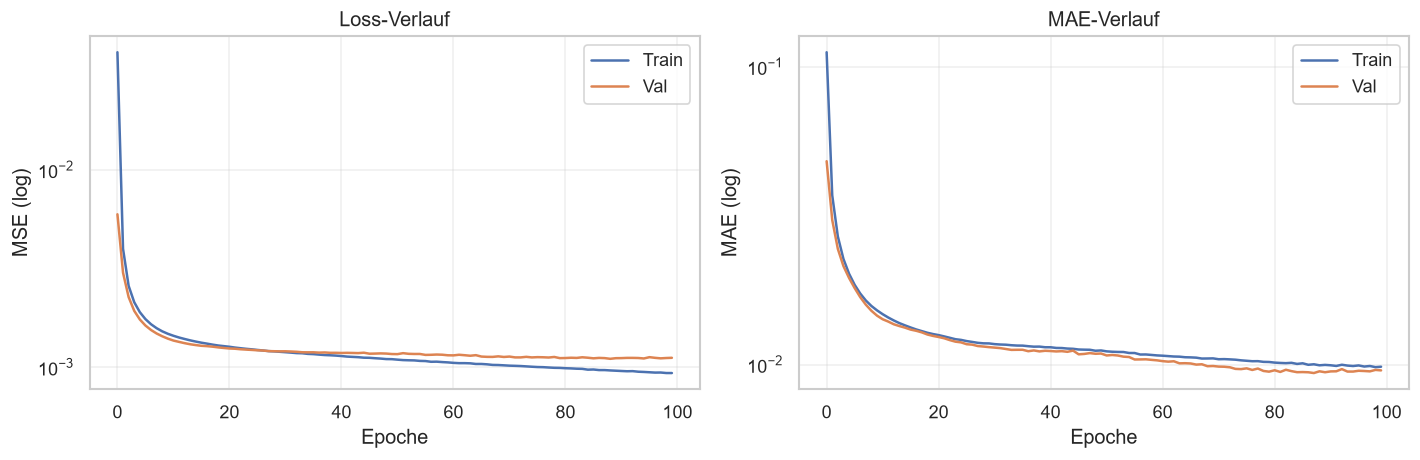

In [15]:
# =========================================================
# Aufgabe 4: Lernkurven
# =========================================================
tk_fig, tk_axes = plt.subplots(1, 2, figsize=(12, 4))

tk_axes[0].plot(tk_history.history["loss"], label="Train")
tk_axes[0].plot(tk_history.history["val_loss"], label="Val")
tk_axes[0].set_yscale("log")
tk_axes[0].set_xlabel("Epoche")
tk_axes[0].set_ylabel("MSE (log)")
tk_axes[0].set_title("Loss-Verlauf")
tk_axes[0].legend()
tk_axes[0].grid(True, alpha=0.3)

tk_axes[1].plot(tk_history.history["mae"], label="Train")
tk_axes[1].plot(tk_history.history["val_mae"], label="Val")
tk_axes[1].set_yscale("log")
tk_axes[1].set_xlabel("Epoche")
tk_axes[1].set_ylabel("MAE (log)")
tk_axes[1].set_title("MAE-Verlauf")
tk_axes[1].legend()
tk_axes[1].grid(True, alpha=0.3)

tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A4_Lernkurven.png", bbox_inches="tight")
plt.show()

In [16]:
# =========================================================
# Aufgabe 4: Evaluation auf dem Testset
# =========================================================
tk_test_loss, tk_test_mae = tk_surrogate_model.evaluate(X_test, Y_test, verbose=0)

display(pd.DataFrame({
    "Kennzahl": ["Test MSE", "Test MAE"],
    "Wert": [round(float(tk_test_loss), 5), round(float(tk_test_mae), 5)],
}))

# --- Fehler pro Dimension ---
tk_Y_pred = tk_surrogate_model.predict(X_test, verbose=0)
tk_per_dim_mae = np.abs(tk_Y_pred - Y_test).mean(axis=0)
tk_per_dim_mse = ((tk_Y_pred - Y_test) ** 2).mean(axis=0)

display(pd.DataFrame({
    "Dimension": TK_DIM_NAMES,
    "MAE": tk_per_dim_mae.round(5),
    "MSE": tk_per_dim_mse.round(5),
}))

,Kennzahl,Wert
0,Test MSE,0.00176
1,Test MAE,0.01016


,Dimension,MAE,MSE
0,x-Position,0.00460,0.00004
1,y-Position,0.00594,0.00007
2,vx,0.00734,0.00010
3,vy,0.00885,0.00015
4,Winkel,0.00443,0.00004
5,Winkelgeschw.,0.01534,0.00104
6,Kontakt links,0.01698,0.00621
7,Kontakt rechts,0.01782,0.00646


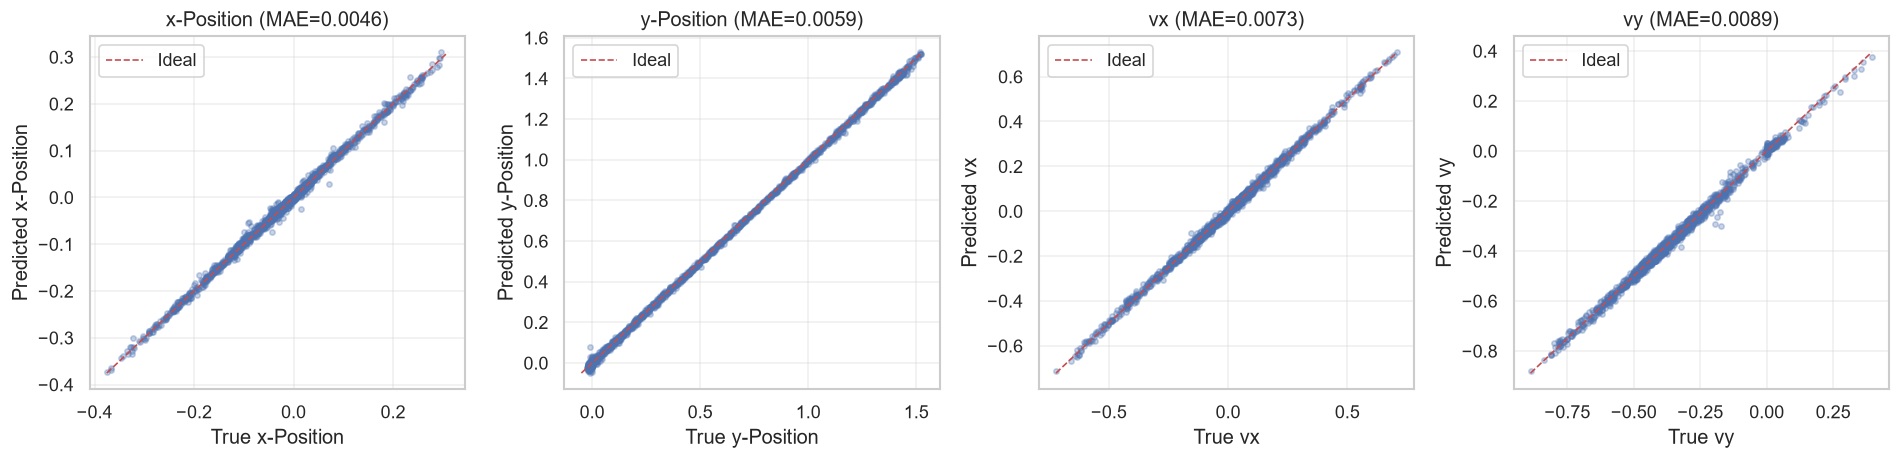

In [17]:
# =========================================================
# Aufgabe 4: Predicted vs. True (4 Dimensionen)
# =========================================================
tk_dims_to_plot = [0, 1, 2, 3]

tk_fig, tk_axes = plt.subplots(1, len(tk_dims_to_plot), figsize=(16, 4))
for tk_ax, tk_dim in zip(tk_axes, tk_dims_to_plot):
    tk_ax.scatter(Y_test[:, tk_dim], tk_Y_pred[:, tk_dim], alpha=0.3, s=10)
    tk_lims = [
        min(Y_test[:, tk_dim].min(), tk_Y_pred[:, tk_dim].min()),
        max(Y_test[:, tk_dim].max(), tk_Y_pred[:, tk_dim].max()),
    ]
    tk_ax.plot(tk_lims, tk_lims, "r--", linewidth=1, label="Ideal")
    tk_ax.set_xlabel(f"True {TK_DIM_NAMES[tk_dim]}")
    tk_ax.set_ylabel(f"Predicted {TK_DIM_NAMES[tk_dim]}")
    tk_ax.set_title(f"{TK_DIM_NAMES[tk_dim]} (MAE={tk_per_dim_mae[tk_dim]:.4f})")
    tk_ax.legend()
    tk_ax.grid(True, alpha=0.3)

tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A4_Pred_vs_True.png", bbox_inches="tight")
plt.show()

In [18]:
# =========================================================
# Aufgabe 4: Baseline-Modell speichern
# =========================================================
tk_surrogate_model.save(str(TK_SURROGATE_BASELINE_PATH))
display(pd.DataFrame({
    "Artefakt": ["Baseline-Surrogatmodell"],
    "Pfad": [str(TK_SURROGATE_BASELINE_PATH)],
}))

,Artefakt,Pfad
0,Baseline-Surrogatmodell,..\models\TomaKing_A4_Surrogat_Baseline.keras


### Interpretation Aufgabe 4

- **Test-Performance:** MSE ≈ **0,00176**, MAE ≈ **0,01016**. Das Modell sagt die nächsten Observations mit einem mittleren Fehler von ca. 0,01 (auf der normalisierten Skala der Observations) sehr präzise vorher.
- **Fehler pro Dimension:** Kontaktflags (`obs_6`, `obs_7`) haben erwartbar höhere MAE (~0,017–0,018), weil sie binäre Sprünge darstellen — ein kleiner Fehler in der kontinuierlichen Prädiktion kann dort zu einem vollständig falschen Flag führen. Die Winkelgeschwindigkeit (`obs_5`) liegt mit MAE ≈ 0,015 ebenfalls über dem Durchschnitt.
- **Lernkurven:** Train- und Val-Loss konvergieren, keine starke Divergenz — das Modell overfittet nicht. Die Kurven sind über 100 Epochen noch leicht fallend, was Spielraum für mehr Epochen oder Early Stopping lässt (Aufgabe 5).
- **Fazit:** Das Surrogatmodell kann die Umgebungsdynamik als deutlich schnelleren Ersatz für die Physik-Simulation dienen.

## Aufgabe 5 – Early Stopping und Hyperparameter-Tuning (10 Punkte)

**Ziel:** Trainingszeit reduzieren und Modellqualität steigern durch:
- **Early Stopping** (Abbruch, wenn `val_loss` über 10 Epochen nicht mehr sinkt, `restore_best_weights=True`)
- **Keras Tuner (RandomSearch)** mit Suchraum:
  - `n_layers` ∈ {1, 2, 3}
  - `n_units` ∈ {32, 64, 96, 128}
  - `activation` ∈ {relu, tanh}
  - `learning_rate` ∈ [1e-4, 1e-2] log-uniform
- **15 Trials**, Ziel: minimales `val_loss`

In [19]:
# =========================================================
# Aufgabe 5: Early Stopping
# =========================================================
tk_surrogate_es, tk_normalizer_es = tk_a4_build_surrogate_model()
tk_normalizer_es.adapt(X_train)

tk_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=0,
)

tf.random.set_seed(TK_SEED)
tk_history_es = tk_surrogate_es.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=200,
    batch_size=64,
    callbacks=[tk_early_stop],
    verbose=0,
)

tk_test_loss_es, tk_test_mae_es = tk_surrogate_es.evaluate(X_test, Y_test, verbose=0)

display(pd.DataFrame({
    "Kennzahl": [
        "Gestoppt nach Epoche",
        "Beste val_loss",
        "Test MSE",
        "Test MAE",
    ],
    "Wert": [
        len(tk_history_es.history["loss"]),
        round(float(min(tk_history_es.history["val_loss"])), 6),
        round(float(tk_test_loss_es), 5),
        round(float(tk_test_mae_es), 5),
    ],
}))

tk_surrogate_es.save(str(TK_SURROGATE_ES_PATH))

,Kennzahl,Wert
0,Gestoppt nach Epoche,64.00000
1,Beste val_loss,0.00112
2,Test MSE,0.00184
3,Test MAE,0.01106


In [20]:
# =========================================================
# Aufgabe 5: Keras Tuner (RandomSearch)
# =========================================================
if TK_TUNER_DIR.exists():
    shutil.rmtree(TK_TUNER_DIR)


def tk_a5_build_model_tunable(hp):
    """MLP mit vom Tuner gewählten Hyperparametern."""
    keras.utils.set_random_seed(TK_SEED)
    tk_n_layers = hp.Int("n_layers", min_value=1, max_value=3, default=2)
    tk_n_units = hp.Int("n_units", min_value=32, max_value=128, step=32, default=64)
    tk_activation = hp.Choice("activation", values=["relu", "tanh"])
    tk_lr = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2,
                     sampling="log", default=1e-3)

    tk_normalizer = keras.layers.Normalization(axis=-1)
    tk_model = keras.Sequential()
    tk_model.add(keras.layers.Input(shape=(12,)))
    tk_model.add(tk_normalizer)
    for _ in range(tk_n_layers):
        tk_model.add(keras.layers.Dense(tk_n_units, activation=tk_activation))
    tk_model.add(keras.layers.Dense(8, activation="linear"))

    tk_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tk_lr),
        loss="mse",
        metrics=["mae"],
    )
    tk_model.normalizer_ = tk_normalizer
    return tk_model


class TkA5AdaptNormalizerCallback(keras.callbacks.Callback):
    """Passt den Normalizer jeder Modellinstanz an X_train an."""
    def on_train_begin(self, logs=None):
        self.model.normalizer_.adapt(X_train)


tk_tuner = kt.RandomSearch(
    tk_a5_build_model_tunable,
    objective="val_loss",
    max_trials=15,
    executions_per_trial=1,
    directory=str(TK_TUNER_DIR),
    project_name="lunar_surrogate",
    seed=TK_SEED,
    overwrite=True,
)

tk_tuner.search(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=100,
    batch_size=64,
    callbacks=[
        TkA5AdaptNormalizerCallback(),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True,
        ),
    ],
    verbose=0,
)

# --- Top-5 Trials ---
tk_trials_table = pd.DataFrame([
    {
        "trial_id": tk_trial.trial_id,
        "val_loss": round(float(tk_trial.score), 6),
        "n_layers": tk_trial.hyperparameters.values["n_layers"],
        "n_units": tk_trial.hyperparameters.values["n_units"],
        "activation": tk_trial.hyperparameters.values["activation"],
        "learning_rate": round(tk_trial.hyperparameters.values["learning_rate"], 6),
    }
    for tk_trial in tk_tuner.oracle.get_best_trials(num_trials=5)
])
display(tk_trials_table)

,trial_id,val_loss,n_layers,n_units,activation,learning_rate
0,13,0.001088,2,128,relu,0.000245
1,04,0.001114,2,32,relu,0.000975
2,14,0.001148,2,64,relu,0.001453
3,09,0.001176,3,32,relu,0.001028
4,02,0.001204,2,32,tanh,0.001715


In [21]:
# =========================================================
# Aufgabe 5: Bestes Modell trainieren und evaluieren
# =========================================================
tk_best_hp = tk_tuner.get_best_hyperparameters(num_trials=1)[0]

display(pd.DataFrame({
    "Hyperparameter": list(tk_best_hp.values.keys()),
    "Wert": [str(v) for v in tk_best_hp.values.values()],
}))

tk_surrogate_tuned = tk_tuner.hypermodel.build(tk_best_hp)
tk_surrogate_tuned.normalizer_.adapt(X_train)
tf.random.set_seed(TK_SEED)
tk_surrogate_tuned.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=100,
    batch_size=64,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True,
    )],
    verbose=0,
)

tk_test_loss_tuned, tk_test_mae_tuned = tk_surrogate_tuned.evaluate(X_test, Y_test, verbose=0)

display(pd.DataFrame({
    "Kennzahl": ["Tuned Test MSE", "Tuned Test MAE"],
    "Wert": [round(float(tk_test_loss_tuned), 6), round(float(tk_test_mae_tuned), 6)],
}))

tk_surrogate_tuned.save(str(TK_SURROGATE_TUNED_PATH))

,Hyperparameter,Wert
0,n_layers,2
1,n_units,128
2,activation,relu
3,learning_rate,0.0002449483373216793


,Kennzahl,Wert
0,Tuned Test MSE,0.001740
1,Tuned Test MAE,0.010086


In [22]:
# =========================================================
# Aufgabe 5: Modellvergleich
# =========================================================
tk_comparison = pd.DataFrame([
    {"Modell": "Baseline (100 Epochen, fix)",
     "Test MSE": float(tk_test_loss), "Test MAE": float(tk_test_mae)},
    {"Modell": "Mit Early Stopping",
     "Test MSE": float(tk_test_loss_es), "Test MAE": float(tk_test_mae_es)},
    {"Modell": "Tuned (Keras Tuner)",
     "Test MSE": float(tk_test_loss_tuned), "Test MAE": float(tk_test_mae_tuned)},
]).round(6)

display(tk_comparison)
tk_comparison.to_csv(TK_DATA_DIR / "TomaKing_A5_Modellvergleich.csv", index=False)

,Modell,Test MSE,Test MAE
0,"Baseline (100 Epochen, fix)",0.001765,0.010162
1,Mit Early Stopping,0.001840,0.011061
2,Tuned (Keras Tuner),0.001740,0.010086


### Interpretation Aufgabe 5

| Modell | Test MSE | Test MAE |
|---|---|---|
| Baseline | 0,001765 | 0,010162 |
| Early Stopping | 0,001840 | 0,011061 |
| Tuned | 0,001740 | 0,010086 |

- **Early Stopping** hat das Training nach **64 Epochen** beendet (statt der maximal 200) und dabei die Test-MSE leicht verschlechtert (0,00184 vs. 0,00177). Der MAE ist minimal schlechter — ein Hinweis darauf, dass die Modelle auf sehr ähnlichem Niveau liegen und der Unterschied im Bereich des Stichprobenrauschens liegt. Der Hauptvorteil liegt in der eingesparten Trainingszeit.
- **Keras Tuner** wählt **`n_layers=2`, `n_units=128`, `activation=relu`, `lr≈2,45e-4`**. Der Tuned-Test-MAE ist mit **0,01009** der Beste der drei Modelle, der Unterschied zum Baseline-Modell ist aber gering.
- **Praktischer Nutzen:** Early Stopping spart Rechenzeit; der Tuner liefert die beste MAE. Beide Techniken sind sinnvoll, wenn man den Surrogat-Ansatz produktiv nutzen will.

    ## Aufgabe 6 – Verteilung und Datenreduktion (20 Punkte)

**Ziel:**
1. Verteilung der Trainingsdaten visualisieren (Aktionen, Observations, Kontaktflags).
2. Stratifizierte Reduktion auf 50/30/20/10/5 % der Schritte **unter Beibehaltung der Aktionsverteilung**.
3. KS-Test: Sind die reduzierten Datensätze verteilungsgleich zum Original?
4. Modellqualität auf reduzierten Datensätzen (Trade-off Datenmenge ↔ Qualität).

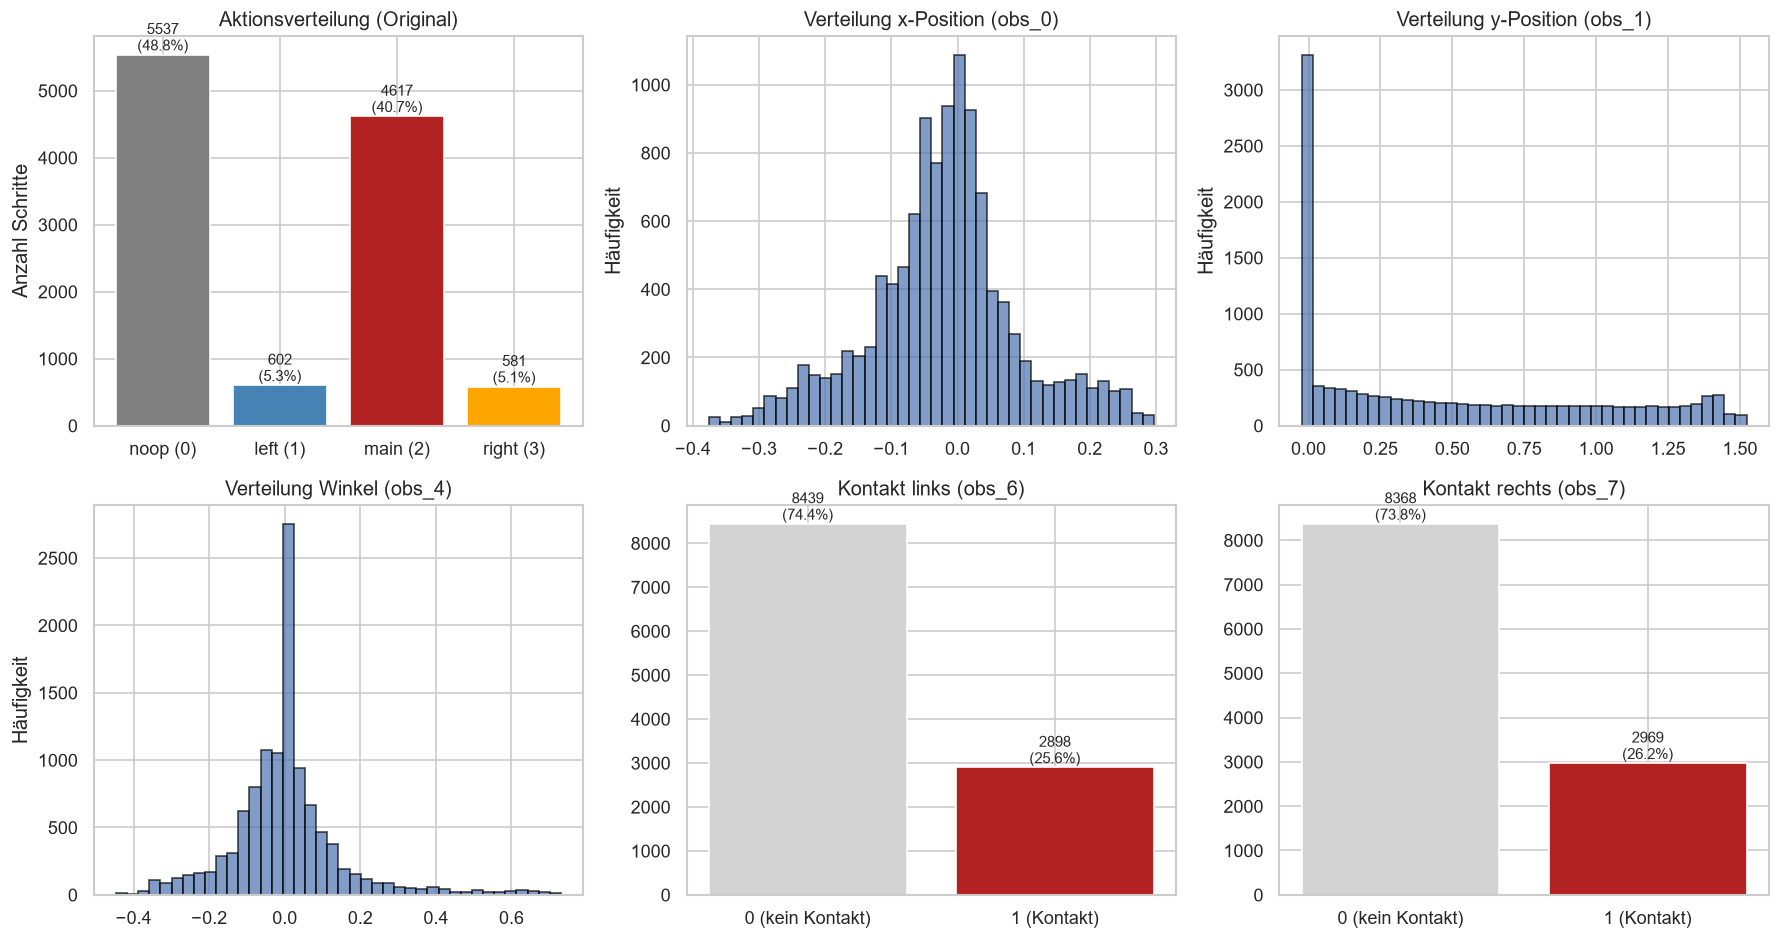

,Aktion,Anzahl,Anteil (%)
0,noop (0),5537,48.8
1,left (1),602,5.3
2,main (2),4617,40.7
3,right (3),581,5.1


In [23]:
# =========================================================
# Aufgabe 6: Verteilung der Trainingsdaten
# =========================================================
tk_fig, tk_axes = plt.subplots(2, 3, figsize=(15, 8))

# (a) Aktionsverteilung
tk_counts = tk_steps_df["action"].value_counts().sort_index()
tk_proportions = tk_counts / tk_counts.sum()
tk_axes[0, 0].bar(
    [TK_ACTION_LABELS[i] for i in tk_counts.index],
    tk_counts.values, color=["grey", "steelblue", "firebrick", "orange"],
)
for tk_i, (tk_cnt, tk_prop) in enumerate(zip(tk_counts.values, tk_proportions.values)):
    tk_axes[0, 0].text(tk_i, tk_cnt, f"{tk_cnt}\n({tk_prop*100:.1f}%)",
                       ha="center", va="bottom", fontsize=9)
tk_axes[0, 0].set_title("Aktionsverteilung (Original)")
tk_axes[0, 0].set_ylabel("Anzahl Schritte")

# (b)-(d) Verteilungen ausgewählter Observations
for tk_ax, tk_dim, tk_name in zip(
    [tk_axes[0, 1], tk_axes[0, 2], tk_axes[1, 0]],
    ["obs_0", "obs_1", "obs_4"],
    ["x-Position", "y-Position", "Winkel"],
):
    tk_ax.hist(tk_steps_df[tk_dim], bins=40, edgecolor="black", alpha=0.7)
    tk_ax.set_title(f"Verteilung {tk_name} ({tk_dim})")
    tk_ax.set_ylabel("Häufigkeit")

# (e)-(f) Kontaktflags
for tk_ax, tk_dim, tk_name in zip(
    [tk_axes[1, 1], tk_axes[1, 2]],
    ["obs_6", "obs_7"],
    ["Kontakt links (obs_6)", "Kontakt rechts (obs_7)"],
):
    tk_counts_flag = tk_steps_df[tk_dim].round().value_counts().sort_index()
    tk_ax.bar(["0 (kein Kontakt)", "1 (Kontakt)"], tk_counts_flag.values,
              color=["lightgrey", "firebrick"])
    for tk_i, tk_v in enumerate(tk_counts_flag.values):
        tk_ax.text(tk_i, tk_v, f"{tk_v}\n({tk_v/len(tk_steps_df)*100:.1f}%)",
                   ha="center", va="bottom", fontsize=9)
    tk_ax.set_title(tk_name)

tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A6_Originalverteilung.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "Aktion": [TK_ACTION_LABELS[i] for i in tk_counts.index],
    "Anzahl": tk_counts.values,
    "Anteil (%)": (tk_proportions.values * 100).round(1),
}))

In [24]:
# =========================================================
# Aufgabe 6: Stratifizierte Reduktion nach Aktion
# =========================================================
def tk_a6_stratified_reduce(df, target_fraction, action_col="action", seed=TK_SEED):
    """Reduziert df auf target_fraction * len(df) Zeilen,
    stratifiziert nach action_col (Aktionsverteilung bleibt erhalten)."""
    _, tk_sampled = train_test_split(
        df,
        test_size=target_fraction,
        stratify=df[action_col],
        random_state=seed,
    )
    return tk_sampled.reset_index(drop=True)


tk_reductions = {}
for tk_frac in TK_REDUCTION_FRACTIONS:
    tk_reductions[tk_frac] = tk_a6_stratified_reduce(tk_steps_df, target_fraction=tk_frac)

display(pd.DataFrame([
    {
        "frac": f"{tk_frac:.0%}",
        "Schritte": len(tk_reductions[tk_frac]),
        "noop": int((tk_reductions[tk_frac]["action"] == 0).sum()),
        "left": int((tk_reductions[tk_frac]["action"] == 1).sum()),
        "main": int((tk_reductions[tk_frac]["action"] == 2).sum()),
        "right": int((tk_reductions[tk_frac]["action"] == 3).sum()),
    }
    for tk_frac in TK_REDUCTION_FRACTIONS
]))

,frac,Schritte,noop,left,main,right
0,50%,5669,2769,301,2309,290
1,30%,3402,1662,181,1385,174
2,20%,2268,1108,120,924,116
3,10%,1134,554,60,462,58
4,5%,567,277,30,231,29


In [25]:
# =========================================================
# Aufgabe 6: KS-Test Original vs. 10%-Subset
# =========================================================

# 10%-Subset aus der stratifizierten Reduktion ziehen
tk_reduced_10 = tk_reductions[0.10]
display(pd.DataFrame({
    "Subset": ["10%"],
    "Schritte": [len(tk_reduced_10)],
}))

# KS-Test pro Observations-Dimension
tk_ks_rows = []
for tk_col in TK_OBS_COLS:
    tk_stat, tk_p = ks_2samp(tk_steps_df[tk_col], tk_reduced_10[tk_col])
    tk_ks_rows.append({
        "Merkmal": tk_col,
        "KS-Statistik": round(float(tk_stat), 4),
        "p-Wert": round(float(tk_p), 4),
        "ähnlich": "ja" if tk_p > 0.05 else "nein",
    })
tk_ks_result = pd.DataFrame(tk_ks_rows)
display(tk_ks_result)

# --- Aktionsverteilung Original vs. 10% vs. 5% ---
tk_action_table = pd.DataFrame({
    "Original": tk_steps_df["action"].value_counts(normalize=True).sort_index(),
    "10%":      tk_reduced_10["action"].value_counts(normalize=True).sort_index(),
    "5%":       tk_reductions[0.05]["action"].value_counts(normalize=True).sort_index(),
}).round(4)
tk_action_table.index = [TK_ACTION_LABELS[i] for i in tk_action_table.index]
display(tk_action_table)

,Subset,Schritte
0,10%,1134


,Merkmal,KS-Statistik,p-Wert,ähnlich
0,obs_0,0.0250,0.5314,ja
1,obs_1,0.0205,0.7732,ja
2,obs_2,0.0148,0.9754,ja
3,obs_3,0.0230,0.6383,ja
4,obs_4,0.0276,0.4041,ja
5,obs_5,0.0284,0.3690,ja
6,obs_6,0.0034,1.0000,ja
7,obs_7,0.0053,1.0000,ja


,Original,10%,5%
noop (0),0.4884,0.4885,0.4885
left (1),0.0531,0.0529,0.0529
main (2),0.4073,0.4074,0.4074
right (3),0.0512,0.0511,0.0511


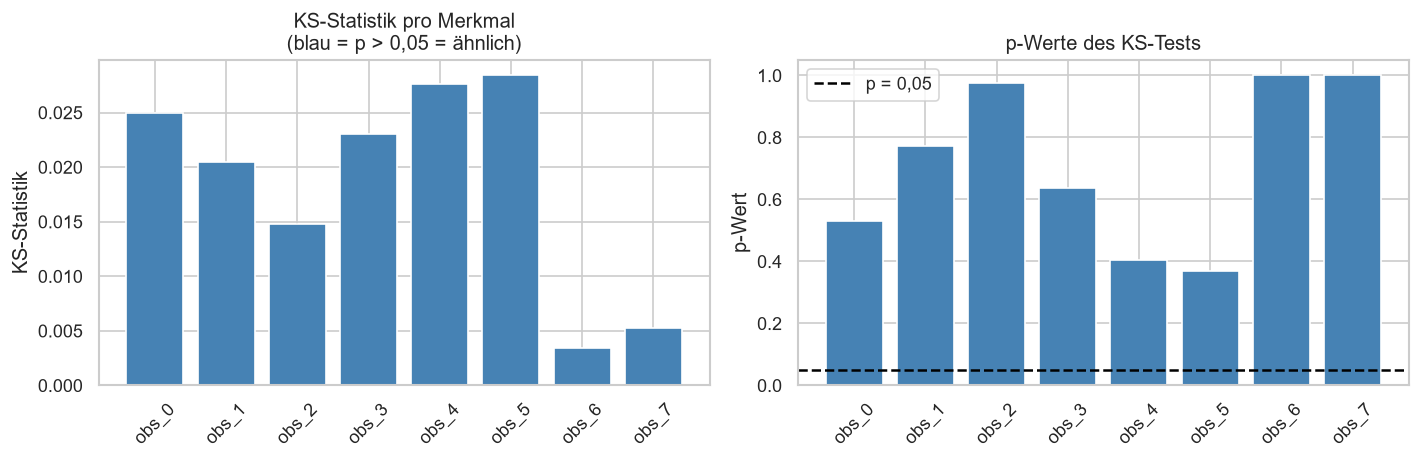

In [26]:
# =========================================================
# Aufgabe 6: KS-Statistik und p-Werte visualisieren
# =========================================================
tk_fig, tk_axes = plt.subplots(1, 2, figsize=(12, 4))

# (links) KS-Statistik
tk_axes[0].bar(
    tk_ks_result["Merkmal"], tk_ks_result["KS-Statistik"],
    color=["steelblue" if p > 0.05 else "firebrick" for p in tk_ks_result["p-Wert"]],
)
tk_axes[0].set_ylabel("KS-Statistik")
tk_axes[0].set_title("KS-Statistik pro Merkmal\n(blau = p > 0,05 = ähnlich)")
tk_axes[0].tick_params(axis="x", rotation=45)

# (rechts) p-Werte mit Signifikanzlinie
tk_axes[1].bar(
    tk_ks_result["Merkmal"], tk_ks_result["p-Wert"],
    color=["steelblue" if p > 0.05 else "firebrick" for p in tk_ks_result["p-Wert"]],
)
tk_axes[1].axhline(0.05, color="black", linestyle="--", label="p = 0,05")
tk_axes[1].set_ylabel("p-Wert")
tk_axes[1].set_title("p-Werte des KS-Tests")
tk_axes[1].legend()
tk_axes[1].tick_params(axis="x", rotation=45)

tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A6_KS_Test.png", bbox_inches="tight")
plt.show()

### Interpretation Aufgabe 6 – Verteilung

- **Aktionsverteilung:** `noop` 48,8 %, `main` 40,7 %, `left` 5,3 %, `right` 5,1 %. Stark unbalanciert — noop und main dominieren zusammen ~90 %.
- **KS-Test Original vs. 10 %-Subset:** Alle 8 Observation-Dimensionen zeigen **p > 0,05**, die reduzierten Daten sind also statistisch nicht von den Originaldaten unterscheidbar. Die Stratifizierung nach Aktion funktioniert.
- **Aktionsverteilung** in 10 % und 5 % weicht nur in der vierten Nachkommastelle von der Originalverteilung ab (z. B. `noop` 0,4884 → 0,4885 → 0,4885).

In [27]:
# =========================================================
# Aufgabe 6: Surrogatmodell auf reduzierten Daten
# =========================================================
def tk_a6_train_eval_on_subset(df_subset, label):
    """Trainiert ein Baseline-Surrogatmodell auf df_subset und liefert die Test-Metriken."""
    tk_X_, tk_Y_ = tk_prepare_xy(df_subset)
    tk_Xtr, tk_Xval, tk_Xtest, tk_Ytr, tk_Yval, tk_Ytest = tk_split_70_15_15(tk_X_, tk_Y_)

    tk_m, tk_norm = tk_a4_build_surrogate_model()
    tk_norm.adapt(tk_Xtr)
    tf.random.set_seed(TK_SEED)
    tk_m.fit(
        tk_Xtr, tk_Ytr,
        validation_data=(tk_Xval, tk_Yval),
        epochs=100, batch_size=64, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=10, restore_best_weights=True,
        )],
    )
    tk_loss, tk_mae = tk_m.evaluate(tk_Xtest, tk_Ytest, verbose=0)
    return {
        "Datensatz": label,
        "n_train": len(tk_Xtr),
        "Test MSE": float(tk_loss),
        "Test MAE": float(tk_mae),
    }


tk_results_subset = [tk_a6_train_eval_on_subset(tk_steps_df, "Original (100%)")]
for tk_frac in TK_REDUCTION_FRACTIONS:
    tk_results_subset.append(
        tk_a6_train_eval_on_subset(tk_reductions[tk_frac], f"Stratifiziert ({int(tk_frac*100)}%)")
    )

tk_results_df = pd.DataFrame(tk_results_subset).round(5)
display(tk_results_df)
tk_results_df.to_csv(TK_DATA_DIR / "TomaKing_A6_Datenverkleinerung.csv", index=False)

,Datensatz,n_train,Test MSE,Test MAE
0,Original (100%),7935,0.00184,0.01106
1,Stratifiziert (50%),3967,0.00118,0.01239
2,Stratifiziert (30%),2380,0.00124,0.01307
3,Stratifiziert (20%),1586,0.00148,0.01604
4,Stratifiziert (10%),793,0.00257,0.01904
5,Stratifiziert (5%),396,0.00114,0.02154


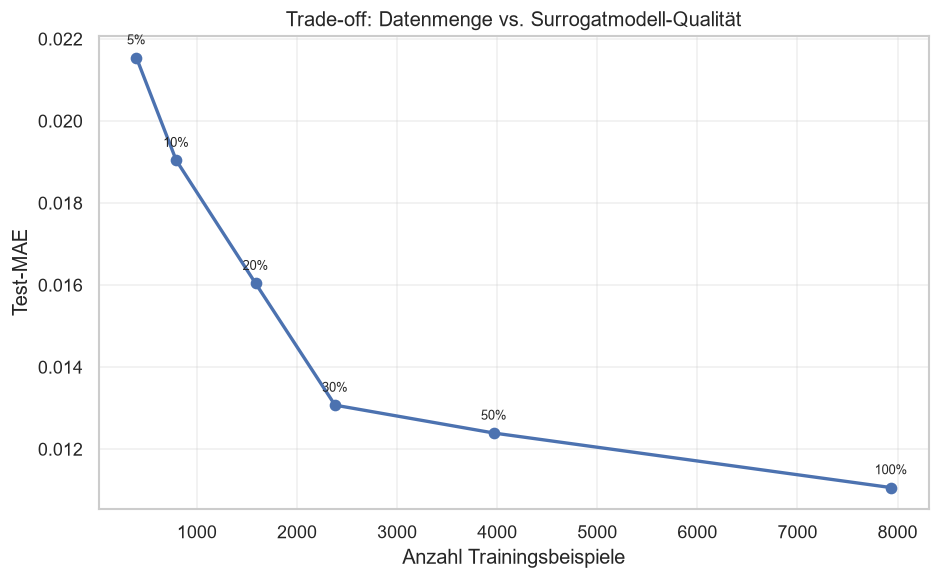

In [28]:
# =========================================================
# Aufgabe 6: Trade-off Datenmenge vs. Modellqualität
# =========================================================
tk_fig, tk_ax = plt.subplots(figsize=(8, 5))
tk_ax.plot(tk_results_df["n_train"], tk_results_df["Test MAE"], marker="o", linewidth=2)
for _, tk_row in tk_results_df.iterrows():
    tk_ax.annotate(
        tk_row["Datensatz"].split("(")[-1].rstrip(")"),
        (tk_row["n_train"], tk_row["Test MAE"]),
        textcoords="offset points", xytext=(0, 8),
        fontsize=8, ha="center",
    )
tk_ax.set_xlabel("Anzahl Trainingsbeispiele")
tk_ax.set_ylabel("Test-MAE")
tk_ax.set_title("Trade-off: Datenmenge vs. Surrogatmodell-Qualität")
tk_ax.grid(True, alpha=0.3)
tk_fig.tight_layout()
tk_fig.savefig(TK_FIG_DIR / "TomaKing_A6_Tradeoff.png", bbox_inches="tight")
plt.show()

### Interpretation Aufgabe 6 – Trade-off

| Datensatz | n_train | Test MSE | Test MAE |
|---|---|---|---|
| Original (100 %) | 7.935 | 0,00184 | 0,01106 |
| Stratifiziert (50 %) | 3.967 | 0,00118 | 0,01239 |
| Stratifiziert (30 %) | 2.380 | 0,00124 | 0,01307 |
| Stratifiziert (20 %) | 1.586 | 0,00148 | 0,01604 |
| Stratifiziert (10 %) | 793 | 0,00257 | 0,01904 |
| Stratifiziert (5 %) | 396 | 0,00114 | 0,02154 |

- **Bis 30 %** bleibt der Test-MAE nahe am Original (Anstieg von 0,01106 auf 0,01307 ≈ +18 %), während die Trainingsmenge auf unter ein Drittel reduziert wird.
- **Bei 20 %** steigt der MAE auf 0,01604, bei **10 % und 5 %** verschlechtert er sich spürbar auf ≈ 0,019 bzw. 0,022. Die MSE-Werte sind nicht monoton, weil einzelne Splits zufällig besser oder schlechter generalisieren — der MAE ist hier robuster interpretierbar.
- **Empfehlung:** Für dieses Surrogatmodell reicht eine **30 %-Stichprobe** (ca. 2.400 Schritte) bei stratifizierter Auswahl, um mit akzeptablem Genauigkeitsverlust Trainingszeit und Speicher zu sparen.

## Zusammenfassung

- **Aufgabe 1:** 50 Episoden, Ø-Reward 281,77 ± 20,60, Ø-Länge 226,74 ± 19,22, keine Korrelation zwischen Länge und Reward (Pearson 0,081).
- **Aufgabe 2:** Fuel-Mapping 0/1/5/1, Ø-Verbrauch 485,36 ± 28,04, Pearson r = 0,463 (mittlerer positiver Zusammenhang zum Reward).
- **Aufgabe 3:** Q3 und Q4 zeigen höhere mittlere Rewards als Q1/Q2, aber nicht streng monoton — Fuel trägt zur Erklärung bei, ohne alleiniger Prädiktor zu sein. Länge ↔ Fuel: Pearson 0,474.
- **Aufgabe 4:** Surrogat-MLP (12 → 64 → 64 → 8) mit Test-MSE 0,00176 und MAE 0,01016.
- **Aufgabe 5:** Early Stopping stoppt nach 64 Epochen und spart Trainingszeit; Keras Tuner findet (2 Layer, 128 Units, ReLU, lr ≈ 2,45e-4) mit leicht verbessertem Test-MAE von 0,01009.
- **Aufgabe 6:** Action-stratifizierte Reduktion erhält die Verteilung (KS-Test p > 0,05 für alle 8 Dimensionen); 30 % der Daten reichen für ein Surrogatmodell mit akzeptabler Qualität (MAE 0,01307 vs. 0,01106 beim Original).